**Regresi Linear**

Contoh 1 Implementasi Code metode Regresi Linear secara manual

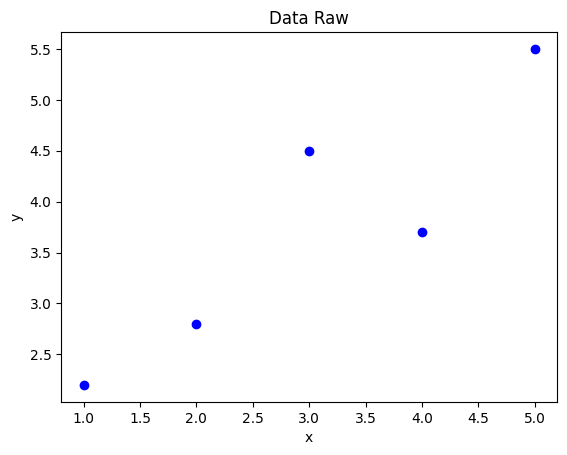

Manual Linear Regression:
Intercept (a): 1.4899999999999998
Slope (b): 0.75


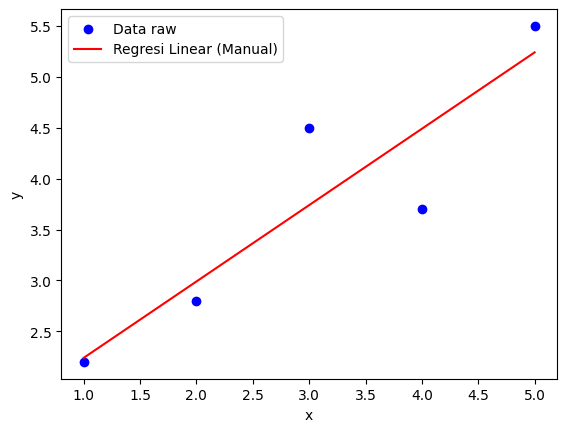


Linear Regression (Manual)
MAE: 0.4079999999999999
MSE: 0.2614
RMSE: 0.5112729212465686
R²: 0.8114541257934218


In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 
 
# Visualisasi data 
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Hitung manual slope (b) dan intercept (a) 
n = len(x) 
b = (n*np.sum(x*y) - np.sum(x)*np.sum(y)) / (n*np.sum(x**2) - (np.sum(x))**2) 
a = np.mean(y) - b*np.mean(x) 
 
# Prediksi 
y_pred = a + b*x 
 
print("Manual Linear Regression:") 
print("Intercept (a):", a) 
print("Slope (b):", b) 
 
# Visualisasi 
plt.scatter(x, y, color='blue', label='Data raw') 
plt.plot(x, y_pred, color='red', label='Regresi Linear (Manual)') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.legend() 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred)))
    print("R²:", r2_score(y_true, y_pred)) 
    
evaluate(y, y_pred, "Linear Regression (Manual)") 

Contoh 2: Implementasi code metode regresi linear menggunakan Scikit Learn 

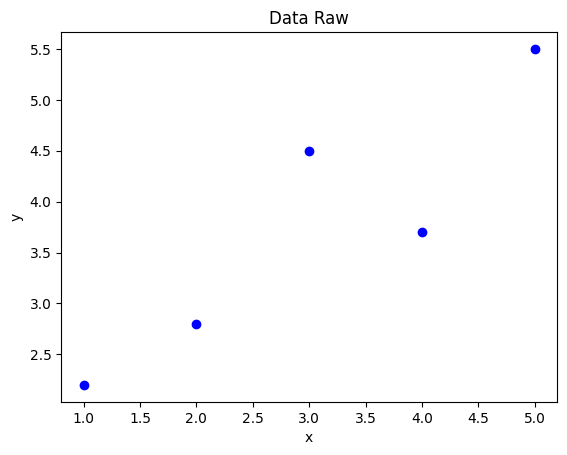

Scikit-learn Linear Regression:
Intercept: 1.4899999999999998
Slope: 0.75


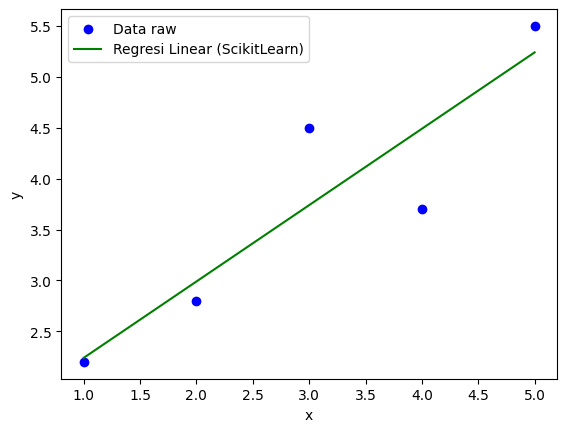


Linear Regression (ScikitLearn)
MAE: 0.4079999999999999
MSE: 0.2614
RMSE: 0.5112729212465686
R²: 0.8114541257934218


In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 
 
# Visualisasi data 
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Prediksi 
from sklearn.linear_model import LinearRegression 
 
x_reshaped = x.reshape(-1, 1)  # reshape agar jadi 2D 
model_lr = LinearRegression() 
model_lr.fit(x_reshaped, y) 
y_pred_lib = model_lr.predict(x_reshaped) 
 
print("Scikit-learn Linear Regression:") 
print("Intercept:", model_lr.intercept_) 
print("Slope:", model_lr.coef_[0]) 
 
# Visualisasi 
plt.scatter(x, y, color='blue', label='Data raw') 
plt.plot(x, y_pred_lib, color='green', label='Regresi Linear (ScikitLearn)') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.legend() 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred))) 
    print("R²:", r2_score(y_true, y_pred)) 
 
evaluate(y, y_pred_lib, "Linear Regression (ScikitLearn)")

**Decision Tree Regession**

Contoh 3: Implementasi code metode Decisiion Tree Regression Manual

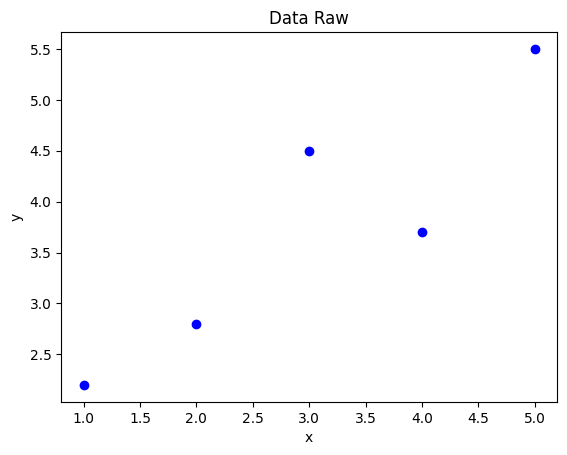

Best split manual Decision Tree: 2


c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


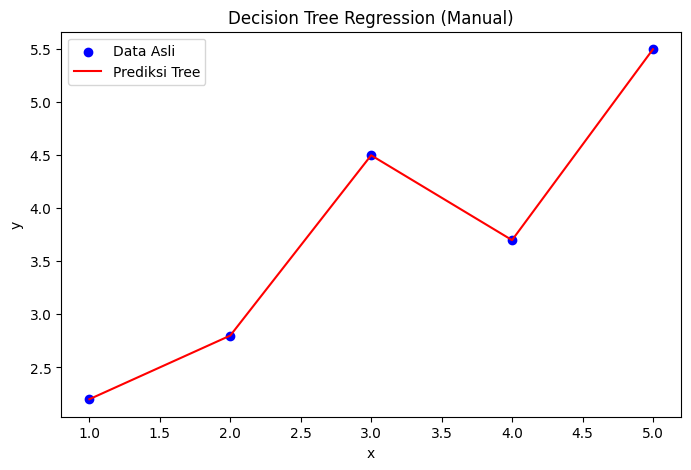


Decision Tree Regression (Manual)
MAE: 0.0
MSE: 0.0
RMSE: 0.0
R²: 1.0


In [3]:
import numpy as np 
import matplotlib.pyplot as plt 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 

# Visualisasi data 
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Mencari Nilai Split Terbaik 
def mse(y): 
    return np.mean((y - np.mean(y))**2) 
 
def best_split(x, y): 
    best_mse = float('inf') 
    best_split_val = None 
    for split in x: 
        left = y[x <= split] 
        right = y[x > split] 
        curr_mse = (len(left)*mse(left) + len(right)*mse(right)) / len(y) 
        if curr_mse < best_mse: 
            best_mse = curr_mse 
            best_split_val = split 
    return best_split_val, best_mse 
 
split, err = best_split(x, y) 
print("Best split manual Decision Tree:", split) 
 
 
# Struktur Node 
class Node: 
    def __init__(self, feature_index=None, threshold=None, left=None, 
right=None, value=None): 
        self.feature_index = feature_index 
        self.threshold = threshold 
        self.left = left 
        self.right = right 
        self.value = value 
 
# Algoritma membangun pohon 
class DecisionTreeRegressorManual: 
    def __init__(self, min_samples_split=2, max_depth=3): 
        self.min_samples_split = min_samples_split 
        self.max_depth = max_depth 
        self.root = None 
 
    def fit(self, x, y): 
        self.root = self._build_tree(x, y, depth=0) 
 
    def _build_tree(self, x, y, depth): 
        n_samples = x.shape[0] 
        if n_samples < self.min_samples_split or depth >= self.max_depth: 
            return Node(value=np.mean(y)) 
 
        best_split_val, best_mse = best_split(x, y) 
        if best_split_val is None: 
            return Node(value=np.mean(y)) 
 
        left_mask = x <= best_split_val 
        right_mask = x > best_split_val 
        left_y = y[left_mask.flatten()] 
        right_y = y[right_mask.flatten()] 
 
        left_subtree = self._build_tree(x[left_mask], left_y, depth + 1) 
        right_subtree = self._build_tree(x[right_mask], right_y, depth + 1) 
        return Node(threshold=best_split_val, left=left_subtree, 
right=right_subtree) 
 
    def _predict_one(self, X, node): 
        if node.value is not None: 
            return node.value 
        if X <= node.threshold: 
            return self._predict_one(X, node.left) 
        else: 
            return self._predict_one(X, node.right) 
 
    def predict(self, X): 
        return np.array([self._predict_one(X, self.root) for X in x.flatten()]) 
 
# Pelatihan dan prediksi 
tree = DecisionTreeRegressorManual(max_depth=3) 
tree.fit(x, y) 
y_pred = tree.predict(x) 
 
# Visualisasi hasil regresi 
plt.figure(figsize=(8,5)) 
plt.scatter(x, y, color='blue', label='Data Asli') 
plt.plot(x, y_pred, color='red', label='Prediksi Tree') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.title('Decision Tree Regression (Manual)') 
plt.legend() 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred))) 
    print("R²:", r2_score(y_true, y_pred)) 
 
evaluate(y, y_pred, "Decision Tree Regression (Manual)") 


Contoh 4: Implementasi Code metode Decision Tree Regression menggunakan Scikit Learn

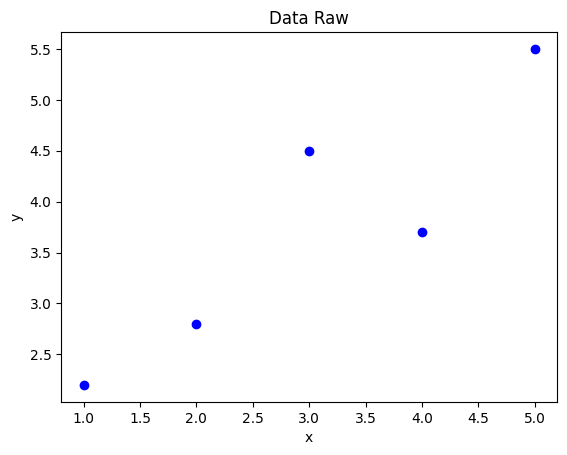

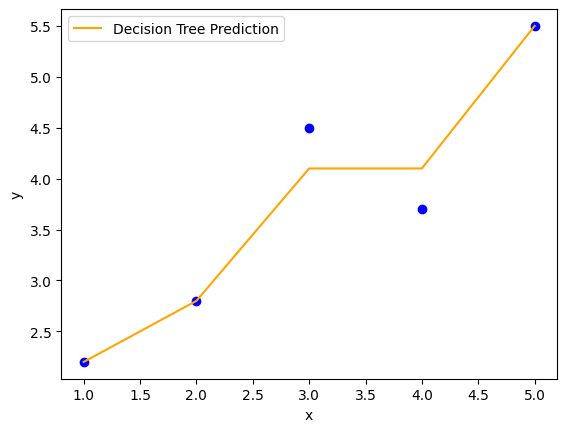


Decision Tree Regression (Scikit Learn)
MAE: 0.15999999999999998
MSE: 0.06399999999999997
RMSE: 0.2529822128134703
R²: 0.9538372763993076


In [4]:
import numpy as np 
import matplotlib.pyplot as plt 
 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 

# Visualisasi data 
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Prediksi 
from sklearn.tree import DecisionTreeRegressor 
 
tree_reg = DecisionTreeRegressor(max_depth=2, random_state=0) 
tree_reg.fit(x_reshaped, y) 
y_pred_tree = tree_reg.predict(x_reshaped) 
 
plt.scatter(x, y, color='blue') 
plt.plot(x, y_pred_tree, color='orange', label='Decision Tree Prediction') 
plt.legend() 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred))) 
    print("R²:", r2_score(y_true, y_pred)) 
 
evaluate(y, y_pred_tree, "Decision Tree Regression (Scikit Learn)") 

**Support Vector Regression**

Contoh 5: Implementasi code metode Support Vector Regression secara Manual 

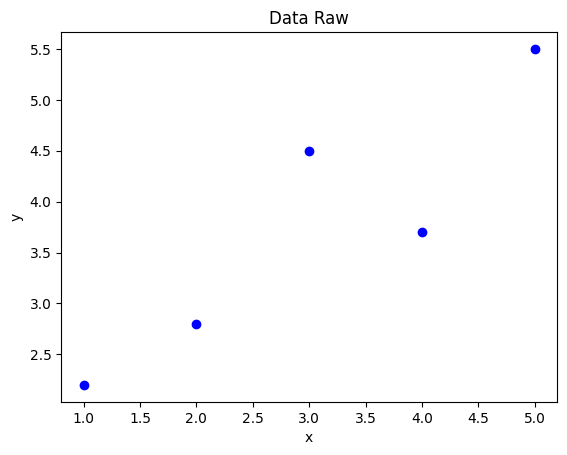

     pcost       dcost       gap    pres   dres
 0: -5.1549e-01 -7.5142e+01  7e+01  7e-16  3e-16
 1: -3.1966e+00 -1.2202e+01  9e+00  9e-16  1e-16
 2: -5.4557e+00 -7.2364e+00  2e+00  2e-16  2e-16
 3: -6.2485e+00 -6.4873e+00  2e-01  3e-16  2e-16
 4: -6.3562e+00 -6.3699e+00  1e-02  2e-16  2e-16
 5: -6.3633e+00 -6.3640e+00  7e-04  3e-16  2e-16
 6: -6.3635e+00 -6.3635e+00  1e-05  8e-16  1e-16
 7: -6.3635e+00 -6.3635e+00  1e-07  3e-16  1e-16
Optimal solution found.


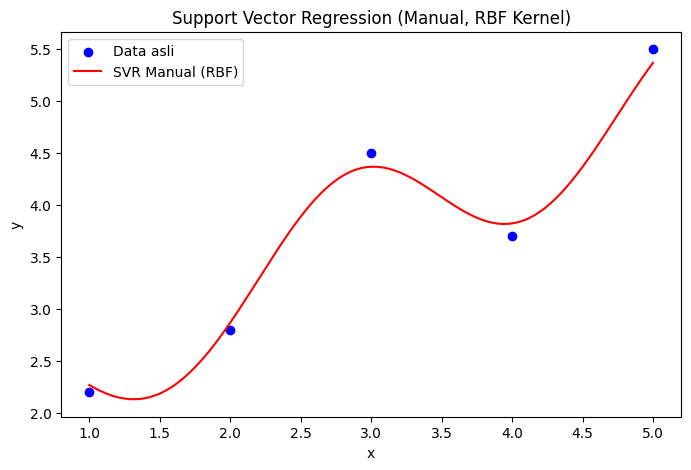


Support Vector Regression (Manual)
MAE: 0.10480846690343179
MSE: 0.011846608972646708
RMSE: 0.10884212866646217
R²: 0.9914551291310973


In [5]:
import numpy as np 
import matplotlib.pyplot as plt 
from cvxopt import solvers 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 
# Visualisasi data 
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 

# Definisi Fungsi Kernel 
def linear_kernel(x1, x2): 
    return np.dot(x1, x2.T) 
 
def rbf_kernel(x1, x2, gamma=0.5): 
    # Radial Basis Function kernel 
    x1_sq = np.sum(x1**2, axis=1).reshape(-1,1) 
    x2_sq = np.sum(x2**2, axis=1) 
    dist_sq = x1_sq + x2_sq - 2*np.dot(x1, x2.T) 
    return np.exp(-gamma * dist_sq) 
 
# Implementasi SVR 
class SVRManual: 
    def __init__(self, C=1.0, epsilon=0.1, kernel='rbf', gamma=0.5): 
        self.C = C 
        self.epsilon = epsilon 
        self.kernel = rbf_kernel if kernel == 'rbf' else linear_kernel 
        self.gamma = gamma 
 
    def fit(self, x, y): 
        n = x.shape[0] 
        K = self.kernel(x, x, self.gamma) 
 
        # Matriks QP untuk dual problem 
        P = np.vstack([ 
            np.hstack([K, -K]), 
            np.hstack([-K, K]) 
        ]) 
        q = np.hstack([self.epsilon - y, self.epsilon + y]) 
 
        G_top = np.vstack([np.eye(2*n), -np.eye(2*n)]) 
        h_top = np.hstack([np.ones(2*n)*self.C, np.zeros(2*n)]) 
 
        A = np.hstack([np.ones(n), -np.ones(n)]).reshape(1, -1) 
        b = np.array([0.0]) 
 
        # Convert to cvxopt matrices 
        from cvxopt import matrix, solvers 
        P = matrix(P) 
        q = matrix(q) 
        G = matrix(G_top) 
        h = matrix(h_top) 
        A = matrix(A) 
        b = matrix(b) 
 
        # Solve QP 
        sol = solvers.qp(P, q, G, h, A, b) 
        alpha = np.array(sol['x']).flatten() 
 
        self.alpha = alpha[:n] 
        self.alpha_star = alpha[n:] 
        self.x = x 
        self.y = y 
 
        # Hitung bias b 
        self.b = np.mean( 
            y - np.sum((self.alpha - self.alpha_star)[:, None] * K, axis=0) 
        ) 
 
 
    def predict(self, x_new): 
        K = self.kernel(x_new, self.x, self.gamma) 
        return np.sum((self.alpha - self.alpha_star)[None, :] * K, axis=1) + self.b 
 
# Inisialisasi dan training 
svr_manual = SVRManual(C=5.0, epsilon=0.1, kernel='rbf', gamma=0.5) 
# Reshape x for SVRManual 
x_reshaped = x.reshape(-1, 1) 
svr_manual.fit(x_reshaped, y) 
 
# Prediksi 
y_pred_eval = svr_manual.predict(x_reshaped) 
 
# Plot 
x_test = np.linspace(1, 5, 200).reshape(-1, 1) 
y_pred = svr_manual.predict(x_test) 
 
 
plt.figure(figsize=(8,5)) 
plt.scatter(x, y, color='blue', label='Data asli') 
plt.plot(x_test, y_pred, color='red', label='SVR Manual (RBF)') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.title('Support Vector Regression (Manual, RBF Kernel)') 
plt.legend() 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred))) 
    print("R²:", r2_score(y_true, y_pred)) 
 
evaluate(y, y_pred_eval, "Support Vector Regression (Manual)") 


Contoh 6: Implementasi code metode Support Vector Regression menggunakan Scikit Learn 

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 
 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 
 
# Visualisasi data
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Bangun Model 
from sklearn.svm import SVR 
from sklearn.preprocessing import StandardScaler 
 
scaler = StandardScaler() 
x_reshaped = x.reshape(-1, 1) 
x_scaled = scaler.fit_transform(x_reshaped) 
 
svr = SVR(kernel='rbf', C=10, epsilon=0.1) 
svr.fit(x_scaled, y) 
 
# Prediksi 
y_pred_svr_eval = svr.predict(x_scaled) 
 
# Plot 
x_test = np.linspace(0, 6, 100).reshape(-1, 1) 
x_test_scaled = scaler.transform(x_test) 
y_pred_svr = svr.predict(x_test_scaled) 
 
 
plt.scatter(x, y, color='blue') 
plt.plot(x_test, y_pred_svr, color='red', label='Library SVR') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.legend() 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred))) 
    print("R²:", r2_score(y_true, y_pred)) 
 
evaluate(y, y_pred_svr_eval, "Support Vector Regression (Scikit Learn)") 

**K-Nearest Neighbor Regression**

Contoh 7: Implementasi code metode K-Nearest Neighbor Regression secara Manual

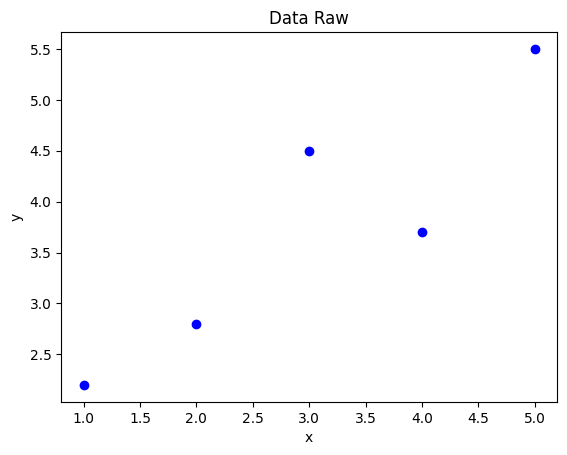

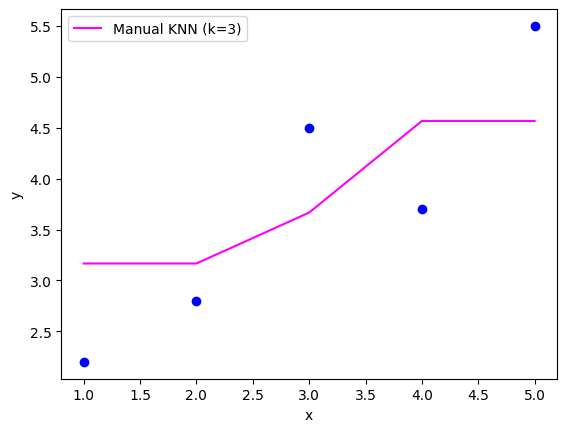


KNN Regression (Manual)
MAE: 0.7933333333333332
MSE: 0.6771111111111109
RMSE: 0.8228676145718161
R²: 0.511604795794063


In [6]:
import numpy as np 
import matplotlib.pyplot as plt 
 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 
 
# Visualisasi data 
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Bangun Model 
def knn_predict(x_train, y_train, x_test, k=3): 
    distances = np.abs(x_train - x_test) 
    k_indices = np.argsort(distances)[:k] 
    return np.mean(y_train[k_indices]) 
 
#Prediksi 
y_pred_knn_manual = np.array([knn_predict(x, y, val, k=3) for val in x]) 
 
plt.scatter(x, y, color='blue') 
plt.plot(x, y_pred_knn_manual, color='magenta', label='Manual KNN (k=3)') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.legend() 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred))) 
    print("R²:", r2_score(y_true, y_pred)) 
 
evaluate(y, y_pred_knn_manual, "KNN Regression (Manual)") 

Contoh 8: Implementasi code metode K-Nearest Neighbor Regression menggunakan Scikit 
Learn 

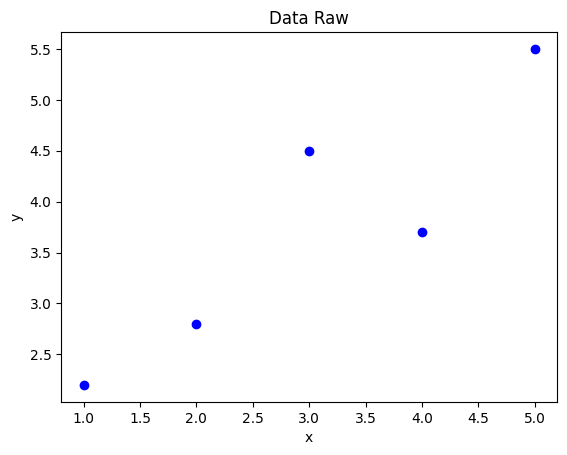

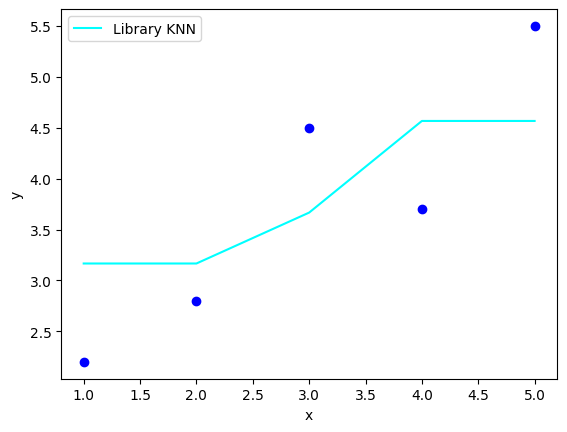


KNN Regression (Scikit Learn)
MAE: 0.7933333333333332
MSE: 0.6771111111111109
RMSE: 0.8228676145718161
R²: 0.511604795794063


In [7]:
import numpy as np 
import matplotlib.pyplot as plt 
 
# Data sederhana 
x = np.array([1, 2, 3, 4, 5]) 
y = np.array([2.2, 2.8, 4.5, 3.7, 5.5]) 
 
# Visualisasi data 
plt.scatter(x, y, color='blue') 
plt.title('Data Raw') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.show() 
 
# Prediksi 
from sklearn.neighbors import KNeighborsRegressor 
 
knn = KNeighborsRegressor(n_neighbors=3) 
knn.fit(x_reshaped, y) 
y_pred_knn = knn.predict(x_reshaped) 
 
# Visualisasi 
plt.scatter(x, y, color='blue') 
plt.plot(x, y_pred_knn, color='cyan', label='Library KNN') 
plt.xlabel('x') 
plt.ylabel('y') 
plt.legend() 
plt.show() 
 
# Evaluasi 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
 
def evaluate(y_true, y_pred, model_name): 
    print(f"\n{model_name}") 
    print("MAE:", mean_absolute_error(y_true, y_pred)) 
    print("MSE:", mean_squared_error(y_true, y_pred)) 
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred))) 
    print("R²:", r2_score(y_true, y_pred)) 

evaluate(y, y_pred_knn, "KNN Regression (Scikit Learn)") 